# 02 · Feature engineering, training & experiment review
Training is run by `python -m heartops.train` (also executed in CI). This notebook inspects the pipeline and the MLflow-tracked results.

In [1]:
import os, pathlib
if pathlib.Path.cwd().name == 'notebooks':
    os.chdir('..')
import warnings; warnings.filterwarnings('ignore')
from IPython.display import Image, display

In [2]:
from sklearn.linear_model import LogisticRegression
from heartops.model import build_pipeline
build_pipeline(LogisticRegression())

,steps,"[('features', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('category', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [3]:
from heartops.train import candidates
{name: grid for name, (_, grid) in candidates().items()}

{'logistic': {'classifier__C': [0.01, 0.1, 1.0, 10.0],
  'classifier__class_weight': [None, 'balanced']},
 'forest': {'classifier__max_depth': [3, 5, None],
  'classifier__min_samples_leaf': [1, 4]}}

## Grid-search results (5-fold stratified CV, training patients only)

In [4]:
import pandas as pd
cols = ['params', 'mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_accuracy', 'mean_test_recall', 'rank_test_roc_auc']
for name in ['logistic', 'forest']:
    print(name)
    display(pd.read_csv(f'artifacts/{name}_search.csv')[cols].sort_values('rank_test_roc_auc'))

logistic


,params,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy,mean_test_recall,rank_test_roc_auc
2,"{'classifier__C': 0.1, 'classifier__class_weig...",0.911344,0.017971,0.851105,0.792095,1
3,"{'classifier__C': 0.1, 'classifier__class_weig...",0.911329,0.018330,0.842687,0.800791,2
5,"{'classifier__C': 1.0, 'classifier__class_weig...",0.906523,0.017576,0.846939,0.818972,3
4,"{'classifier__C': 1.0, 'classifier__class_weig...",0.906495,0.019701,0.847024,0.783794,4
7,"{'classifier__C': 10.0, 'classifier__class_wei...",0.905561,0.014485,0.838690,0.801581,5
6,"{'classifier__C': 10.0, 'classifier__class_wei...",0.904514,0.015750,0.851020,0.801581,6
1,"{'classifier__C': 0.01, 'classifier__class_wei...",0.899036,0.025721,0.838690,0.792095,7
0,"{'classifier__C': 0.01, 'classifier__class_wei...",0.898699,0.025664,0.809949,0.693281,8


forest


,params,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy,mean_test_recall,rank_test_roc_auc
5,"{'classifier__max_depth': None, 'classifier__m...",0.898475,0.028990,0.818027,0.773913,1
0,"{'classifier__max_depth': 3, 'classifier__min_...",0.896081,0.027039,0.818027,0.773518,2
1,"{'classifier__max_depth': 3, 'classifier__min_...",0.896029,0.027683,0.822109,0.782609,3
3,"{'classifier__max_depth': 5, 'classifier__min_...",0.895786,0.028120,0.809694,0.791700,4
2,"{'classifier__max_depth': 5, 'classifier__min_...",0.895481,0.030745,0.809694,0.755731,5
4,"{'classifier__max_depth': None, 'classifier__m...",0.886599,0.039308,0.813776,0.764822,6


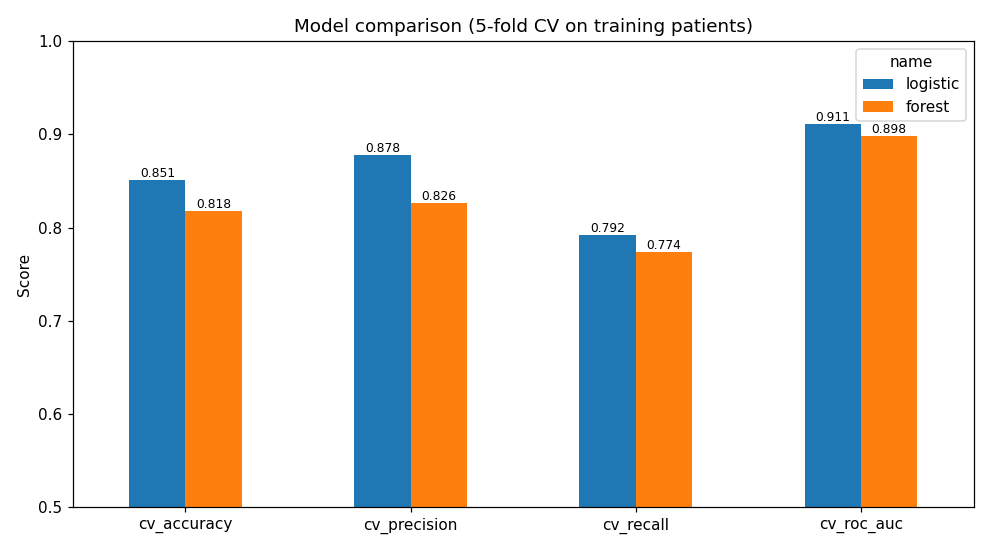

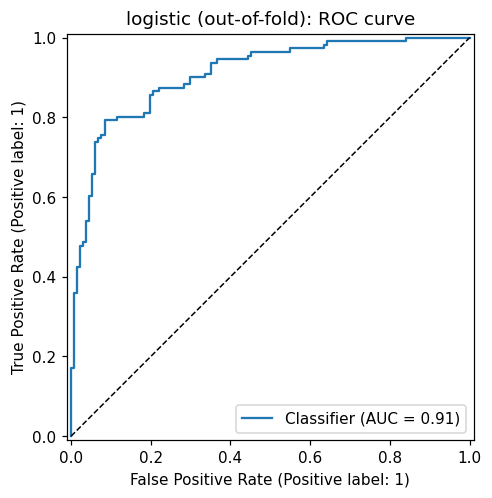

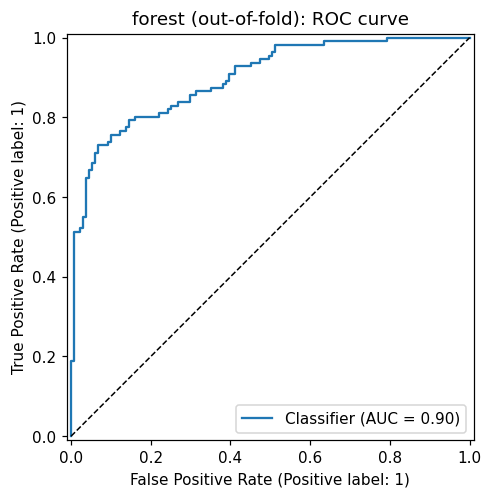

In [5]:
display(Image('reports/figures/model_comparison.png'))
for name in ['logistic', 'forest']:
    display(Image(f'artifacts/{name}_cv_roc_curve.png', width=380))

## MLflow runs

In [6]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
runs = mlflow.search_runs(experiment_names=['heartops-cleveland'])
runs[[c for c in runs.columns if c in ('tags.mlflow.runName', 'metrics.cv_roc_auc', 'metrics.cv_accuracy', 'metrics.heldout_roc_auc', 'metrics.heldout_accuracy')]].sort_values('tags.mlflow.runName')

2026/10/20 19:29:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/20 19:29:43 INFO mlflow.store.db.utils: Updating database tables


2026-10-20 19:29:43 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-10-20 19:29:43 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


2026-10-20 19:29:43 INFO  [alembic.runtime.migration] Context impl SQLiteImpl.


2026-10-20 19:29:43 INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


,metrics.heldout_accuracy,metrics.heldout_roc_auc,metrics.cv_accuracy,metrics.cv_roc_auc,tags.mlflow.runName
7,NaN,NaN,0.818027,0.898475,forest
6,NaN,NaN,0.818027,0.896081,forest-trial-0
5,NaN,NaN,0.822109,0.896029,forest-trial-1
4,NaN,NaN,0.809694,0.895481,forest-trial-2
3,NaN,NaN,0.809694,0.895786,forest-trial-3
2,NaN,NaN,0.813776,0.886599,forest-trial-4
1,NaN,NaN,0.818027,0.898475,forest-trial-5
16,NaN,NaN,0.851105,0.911344,logistic
15,NaN,NaN,0.809949,0.898699,logistic-trial-0
14,NaN,NaN,0.838690,0.899036,logistic-trial-1


## Selected model on the held-out 20%

In [7]:
import json
m = json.load(open('artifacts/metrics.json'))
print('selected:', m['selected'], m['candidates'][0]['params'] if m['selected']=='logistic' else m['candidates'][1]['params'])
pd.Series(m['heldout_metrics']).round(4)

selected: logistic {'classifier__C': 0.1, 'classifier__class_weight': None}


accuracy     0.8852
precision    0.8387
recall       0.9286
roc_auc      0.9610
dtype: float64

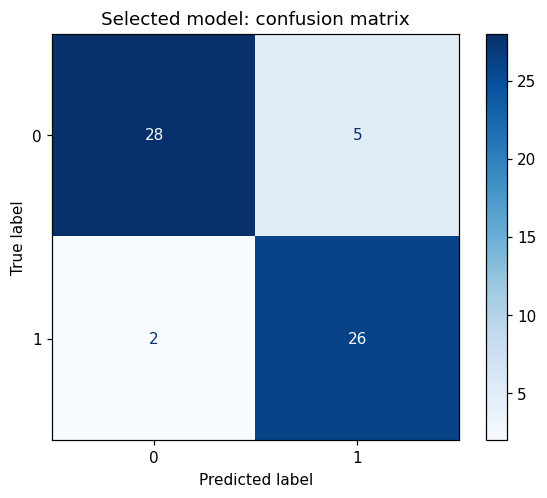

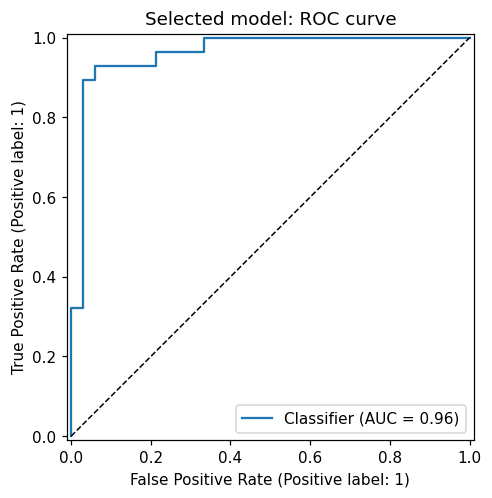

In [8]:
display(Image('reports/figures/confusion_matrix.png', width=380))
display(Image('reports/figures/roc_curve.png', width=380))